In [1]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset
from torch.utils.data import DataLoader, random_split
from tqdm import tqdm
import wandb

There are a max of four classes in the dataset: background, object1, object2, and object3. However, some images may only contain a subset of these classes. For example, some images may only contain background and object1, while others may contain all four classes. The number of classes present in each image can vary, but it will always be between 2 and 4.

Number of classes in mask: 4
Number of unique values in depth map: 254


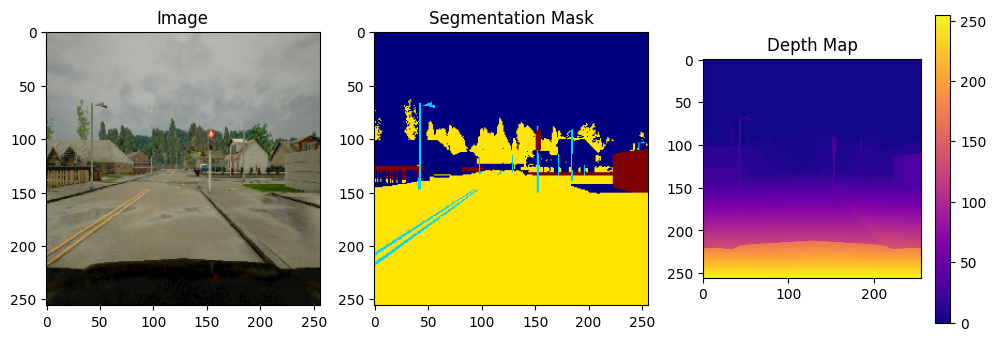

Number of classes in mask: 3
Number of unique values in depth map: 256


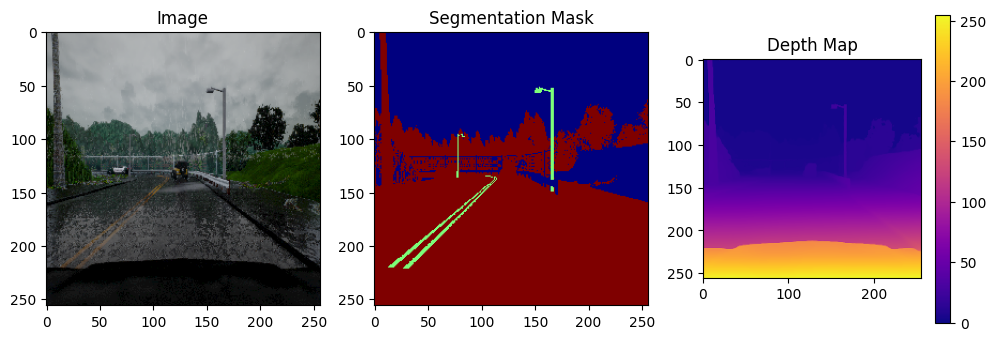

Number of classes in mask: 2
Number of unique values in depth map: 239


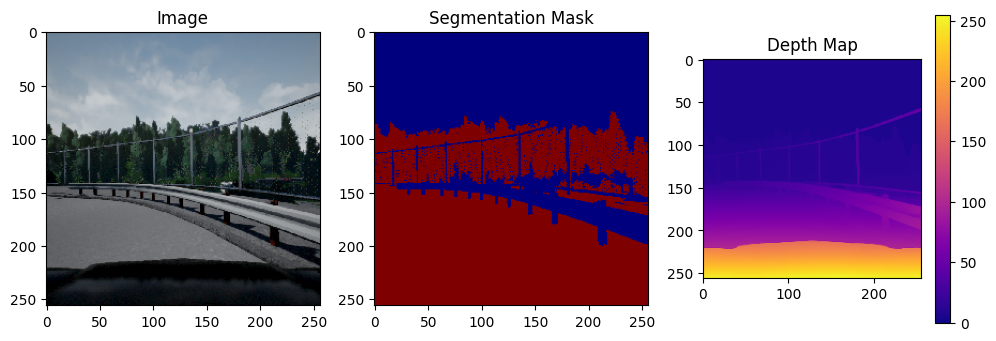

In [ ]:
# Visualise a few images to understand the dataset better.

root = "data/train"

alr_visualised = []
for img_index in range(2000):
    if len(alr_visualised) == 3: break
    
    img_path = os.path.join(root, "images", os.listdir(root + "/images")[img_index])
    mask_path = os.path.join(root, "labels", os.listdir(root + "/labels")[img_index])
    depth_path = os.path.join(root, "depth", os.listdir(root + "/depth")[img_index])

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    depth = cv2.imread(depth_path, cv2.IMREAD_GRAYSCALE).astype(np.float32)

    num_classes = np.unique(mask).size
    if num_classes in alr_visualised:
        continue
    alr_visualised.append(num_classes)

    plt.figure(figsize=(12,4))
    plt.subplot(1,3,1)
    plt.title("Image")
    plt.imshow(img)

    plt.subplot(1,3,2)
    plt.title("Segmentation Mask")
    plt.imshow(mask, cmap='jet')
    print("Number of classes in mask:", num_classes)

    plt.subplot(1,3,3)
    plt.title("Depth Map")
    plt.imshow(depth, cmap='plasma')
    plt.colorbar()
    print("Number of unique values in depth map:", np.unique(depth).size)

    plt.show()

In [4]:
class MultiTaskDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root = root_dir
        self.transform = transform

        self.images = sorted(os.listdir(os.path.join(root_dir, "images")))
        self.masks = sorted(os.listdir(os.path.join(root_dir, "labels")))
        self.depths = sorted(os.listdir(os.path.join(root_dir, "depth")))

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = os.path.join(self.root, "images", self.images[idx])
        mask_path = os.path.join(self.root, "labels", self.masks[idx])
        depth_path = os.path.join(self.root, "depth", self.depths[idx])

        # Image
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = img.astype(np.float32) / 255.0

        # Mask
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE).astype(np.int64)

        # Depth
        depth = cv2.imread(depth_path, cv2.IMREAD_GRAYSCALE).astype(np.float32)

        # Normalization (global-like)
        depth = depth / 255.0   # assuming 8-bit depth

        # To tensor
        img = torch.from_numpy(img).permute(2, 0, 1)
        mask = torch.from_numpy(mask)
        depth = torch.from_numpy(depth).unsqueeze(0)

        return img, mask, depth

Depth maps were normalized using a fixed scaling factor (256) instead of per-image normalization to preserve relative depth consistency across samples.

In [15]:
full_dataset = MultiTaskDataset(root_dir="data/train")
test_dataset = MultiTaskDataset(root_dir="data/test")

val_size = int(0.25 * len(full_dataset))
train_size = len(full_dataset) - val_size

generator = torch.Generator().manual_seed(42)  # reproducible split
train_dataset, val_dataset = random_split(
    full_dataset, [train_size, val_size], generator=generator
)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

print(f"Train samples: {len(train_dataset)}")
print(f"Val samples: {len(val_dataset)}")

Train samples: 1500
Val samples: 500


In [16]:
img, mask, depth = train_dataset[0]
print("Image shape:", img.shape)
print("Mask shape:", mask.shape)
print("Depth shape:", depth.shape)

Image shape: torch.Size([3, 256, 256])
Mask shape: torch.Size([256, 256])
Depth shape: torch.Size([1, 256, 256])


----

In [7]:
# Basic conv block
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU()
        )

    def forward(self, x):
        return self.net(x)

In [ ]:
class UNet(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        # Encoder
        self.enc1 = ConvBlock(3, 64)
        self.enc2 = ConvBlock(64, 128)
        self.enc3 = ConvBlock(128, 256)
        self.enc4 = ConvBlock(256, 512)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = ConvBlock(512, 1024)

        # Decoder
        self.up4 = nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.dec4 = ConvBlock(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec3 = ConvBlock(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec2 = ConvBlock(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec1 = ConvBlock(128, 64)

        # Heads
        self.seg_head = nn.Conv2d(64, num_classes, 1)
        self.depth_head = nn.Conv2d(64, 1, 1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        # Decoder
        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        seg = self.seg_head(d1)
        depth = self.depth_head(d1)

        return seg, depth

Segmentation head

Output: (B, num_classes, H, W)

Loss: CrossEntropyLoss (no softmax needed)

Depth head

Output: (B, 1, H, W)

Loss: MSELoss

In [ ]:
class MultiTaskLoss(nn.Module):
    def __init__(self):
        super().__init__()

        # log(sigma^2)
        self.log_var_seg = nn.Parameter(torch.zeros(1))
        self.log_var_depth = nn.Parameter(torch.zeros(1))

    def forward(self, seg_pred, seg_gt, depth_pred, depth_gt):
        seg_loss = F.cross_entropy(seg_pred, seg_gt)
        depth_loss = F.mse_loss(depth_pred, depth_gt)

        # uncertainty weighting
        loss = (
            torch.exp(-self.log_var_seg) * seg_loss + self.log_var_seg +
            torch.exp(-self.log_var_depth) * depth_loss + self.log_var_depth
        )
        loss += 0.01 * (self.log_var_seg**2 + self.log_var_depth**2)

        return loss, seg_loss, depth_loss

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [17]:
def compute_miou(pred, target, num_classes):
    pred = torch.argmax(pred, dim=1)

    ious = []
    for cls in range(num_classes):
        intersection = ((pred == cls) & (target == cls)).sum().float()
        union = ((pred == cls) | (target == cls)).sum().float()

        if union == 0:
            continue

        ious.append(intersection / union)

    return sum(ious) / len(ious) if ious else torch.tensor(0.0)


def compute_rmse(pred, target):
    return torch.sqrt(F.mse_loss(pred, target))

In [ ]:
model = UNet(num_classes=4).to(device)
loss_fn = MultiTaskLoss().to(device)

optimizer = torch.optim.Adam(
    list(model.parameters()) + list(loss_fn.parameters()),
    lr=1e-4
)

wandb.init(
    project="multitask-unet",
    config={
        "lr": 1e-4,
        "batch_size": 16,
        "epochs": 20
    }
)

depth_loss,█▄▆▃▁▁▁▁▁▁
epoch,▁▂▃▃▄▅▆▆▇█
log_var_depth,█▇▆▆▅▄▃▃▂▁
log_var_seg,█▇▆▆▅▄▃▂▂▁
seg_loss,█▅▄▃▂▂▁▁▁▁
train_RMSE,█▃▃▂▂▂▁▁▁▁
train_loss,█▅▅▄▃▃▂▂▁▁
train_mIoU,▁▃▄▅▆▇▇███
val_RMSE,█▄▅▄▂▂▁▂▁▁
val_loss,█▆▅▄▄▃▂▂▁▁
+1,...


In [19]:
def log_predictions_batch(imgs, masks, depths, seg_pred, depth_pred, num_samples=10):
    imgs = imgs.cpu()
    masks = masks.cpu()
    depths = depths.cpu()
    seg_pred = seg_pred.cpu()
    depth_pred = depth_pred.cpu()

    num_samples = min(num_samples, imgs.shape[0])
    images_to_log = []

    for i in range(num_samples):
        img = imgs[i].permute(1,2,0).numpy()
        gt_mask = masks[i].numpy()
        pred_mask = torch.argmax(seg_pred[i], dim=0).numpy()

        gt_depth = depths[i].squeeze().numpy()
        pred_depth = depth_pred[i].squeeze().numpy()

        fig, axs = plt.subplots(1, 5, figsize=(15,3))

        axs[0].imshow(img)
        axs[0].set_title("Image")

        axs[1].imshow(gt_mask, cmap='jet')
        axs[1].set_title("GT Mask")

        axs[2].imshow(pred_mask, cmap='jet')
        axs[2].set_title("Pred Mask")

        axs[3].imshow(gt_depth, cmap='plasma')
        axs[3].set_title("GT Depth")

        axs[4].imshow(pred_depth, cmap='plasma')
        axs[4].set_title("Pred Depth")

        for ax in axs:
            ax.axis("off")

        images_to_log.append(wandb.Image(fig))
        plt.close(fig)

    wandb.log({"Predictions": images_to_log})

In [20]:
num_epochs = 20

for epoch in range(num_epochs):

    # ================= TRAIN =================
    model.train()
    train_loss = 0
    train_miou = 0
    train_rmse = 0

    for imgs, masks, depths in tqdm(train_loader):
        imgs = imgs.to(device)
        masks = masks.to(device)
        depths = depths.to(device)

        seg_pred, depth_pred = model(imgs)

        loss, seg_loss, depth_loss = loss_fn(
            seg_pred, masks, depth_pred, depths
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        train_miou += compute_miou(seg_pred, masks, 4).item()
        train_rmse += compute_rmse(depth_pred, depths).item()

    train_loss /= len(train_loader)
    train_miou /= len(train_loader)
    train_rmse /= len(train_loader)

    # ================= VALIDATION =================
    model.eval()
    val_loss = 0
    val_miou = 0
    val_rmse = 0

    with torch.no_grad():
        for i, (imgs, masks, depths) in enumerate(val_loader):
            imgs = imgs.to(device)
            masks = masks.to(device)
            depths = depths.to(device)

            seg_pred, depth_pred = model(imgs)

            # log only first batch
            if i == 0:
                log_predictions_batch(imgs, masks, depths, seg_pred, depth_pred)

            loss, seg_loss, depth_loss = loss_fn(seg_pred, masks, depth_pred, depths)

            val_loss += loss.item()
            val_miou += compute_miou(seg_pred, masks, 4).item()
            val_rmse += compute_rmse(depth_pred, depths).item()

    val_loss /= len(val_loader)
    val_miou /= len(val_loader)
    val_rmse /= len(val_loader)

    # ================= LOG =================
    wandb.log({
        "epoch": epoch,

        "train_loss": train_loss,
        "train_mIoU": train_miou,
        "train_RMSE": train_rmse,

        "val_loss": val_loss,
        "val_mIoU": val_miou,
        "val_RMSE": val_rmse,

        # individual losses
        "seg_loss": seg_loss.item(),
        "depth_loss": depth_loss.item(),

        # learnable weights
        "log_var_seg": loss_fn.log_var_seg.item(),
        "log_var_depth": loss_fn.log_var_depth.item()
    })

    print(f"Epoch {epoch}: "
          f"Train Loss={train_loss:.4f}, Val Loss={val_loss:.4f}, "
          f"mIoU={val_miou:.4f}, RMSE={val_rmse:.4f}")

100%|██████████| 94/94 [00:41<00:00,  2.24it/s]


Epoch 0: Train Loss=0.6871, Val Loss=0.4377, mIoU=0.5061, RMSE=0.0875


100%|██████████| 94/94 [00:42<00:00,  2.22it/s]


Epoch 1: Train Loss=0.3582, Val Loss=0.2970, mIoU=0.5417, RMSE=0.0658


100%|██████████| 94/94 [00:39<00:00,  2.38it/s]


Epoch 2: Train Loss=0.2393, Val Loss=0.2050, mIoU=0.6282, RMSE=0.0637


... (30 outputs left out)

100%|██████████| 94/94 [00:38<00:00,  2.46it/s]


Epoch 18: Train Loss=-0.2990, Val Loss=-0.3050, mIoU=0.8669, RMSE=0.0414


100%|██████████| 94/94 [00:40<00:00,  2.35it/s]


Epoch 19: Train Loss=-0.3288, Val Loss=-0.3310, mIoU=0.8771, RMSE=0.0384


---

In [25]:
class UNetNoSkip(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        # Encoder
        self.enc1 = ConvBlock(3, 64)
        self.enc2 = ConvBlock(64, 128)
        self.enc3 = ConvBlock(128, 256)
        self.enc4 = ConvBlock(256, 512)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = ConvBlock(512, 1024)

        # Decoder
        self.up4 = nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.dec4 = ConvBlock(512, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec3 = ConvBlock(256, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec2 = ConvBlock(128, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec1 = ConvBlock(64, 64)

        # Heads
        self.seg_head = nn.Conv2d(64, num_classes, 1)
        self.depth_head = nn.Conv2d(64, 1, 1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        # Decoder
        d4 = self.up4(b)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = self.dec1(d1)

        seg = self.seg_head(d1)
        depth = self.depth_head(d1)

        return seg, depth

In [28]:
model = UNetNoSkip(4)
loss_fn = MultiTaskLoss().to(device)

optimizer = torch.optim.Adam(
    list(model.parameters()) + list(loss_fn.parameters()),
    lr=1e-4
)

wandb.init(
    project="multitask-unet",
    config={
        "lr": 1e-4,
        "batch_size": 16,
        "epochs": 20
    }
)

depth_loss,▆▃▃▂▂▃▂▂▁▁▂▁▁▁▁▁█▁▁▁
epoch,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
log_var_depth,██▇▇▇▆▆▅▅▅▄▄▄▃▃▂▂▂▁▁
log_var_seg,██▇▇▆▆▆▅▅▅▄▄▃▃▃▂▂▂▁▁
seg_loss,█▆▅▄▃▂▂▂▂▂▂▁▁▁▁▁▃▁▁▁
train_RMSE,█▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▂▁▁
train_loss,█▆▅▄▄▄▃▃▃▃▂▂▂▂▂▂▂▂▁▁
train_mIoU,▁▂▃▄▅▅▆▆▇▇▇▇████▇▆██
val_RMSE,▇▄▄▄▃▄▃▂▂▂▂▂▁▁▂▁█▂▁▁
val_loss,█▇▆▅▅▄▄▄▃▃▃▃▂▂▂▂▃▂▁▁
+1,...


In [29]:
num_epochs = 20

for epoch in range(num_epochs):

    # ================= TRAIN =================
    model.train()
    train_loss = 0
    train_miou = 0
    train_rmse = 0

    for imgs, masks, depths in tqdm(train_loader):
        imgs = imgs.to(device)
        masks = masks.to(device)
        depths = depths.to(device)

        seg_pred, depth_pred = model(imgs)

        loss, seg_loss, depth_loss = loss_fn(
            seg_pred, masks, depth_pred, depths
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        train_miou += compute_miou(seg_pred, masks, 4).item()
        train_rmse += compute_rmse(depth_pred, depths).item()

    train_loss /= len(train_loader)
    train_miou /= len(train_loader)
    train_rmse /= len(train_loader)

    # ================= VALIDATION =================
    model.eval()
    val_loss = 0
    val_miou = 0
    val_rmse = 0

    with torch.no_grad():
        for i, (imgs, masks, depths) in enumerate(val_loader):
            imgs = imgs.to(device)
            masks = masks.to(device)
            depths = depths.to(device)

            seg_pred, depth_pred = model(imgs)

            # log only first batch
            if i == 0:
                log_predictions_batch(imgs, masks, depths, seg_pred, depth_pred)

            loss, seg_loss, depth_loss = loss_fn(seg_pred, masks, depth_pred, depths)

            val_loss += loss.item()
            val_miou += compute_miou(seg_pred, masks, 4).item()
            val_rmse += compute_rmse(depth_pred, depths).item()

    val_loss /= len(val_loader)
    val_miou /= len(val_loader)
    val_rmse /= len(val_loader)

    # ================= LOG =================
    wandb.log({
        "epoch": epoch,

        "train_loss": train_loss,
        "train_mIoU": train_miou,
        "train_RMSE": train_rmse,

        "val_loss": val_loss,
        "val_mIoU": val_miou,
        "val_RMSE": val_rmse,

        # individual losses
        "seg_loss": seg_loss.item(),
        "depth_loss": depth_loss.item(),

        # learnable weights
        "log_var_seg": loss_fn.log_var_seg.item(),
        "log_var_depth": loss_fn.log_var_depth.item()
    })

    print(f"Epoch {epoch}: "
          f"Train Loss={train_loss:.4f}, Val Loss={val_loss:.4f}, "
          f"mIoU={val_miou:.4f}, RMSE={val_rmse:.4f}")

  0%|          | 0/94 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]


RuntimeError: Input type (torch.cuda.FloatTensor) and weight type (torch.FloatTensor) should be the same